In [230]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn joblib

In [231]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import joblib

In [232]:
df=pd.read_csv("credit_risk_dataset.csv")

In [233]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [234]:
df.shape

(32581, 12)

In [235]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 32581
Columns: 12


In [236]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [237]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [238]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [239]:
df["loan_status"].value_counts()

,count
loan_status,
0,25473
1,7108


In [240]:
df["loan_status"].value_counts(normalize=True) * 100

,proportion
loan_status,
0,78.183604
1,21.816396


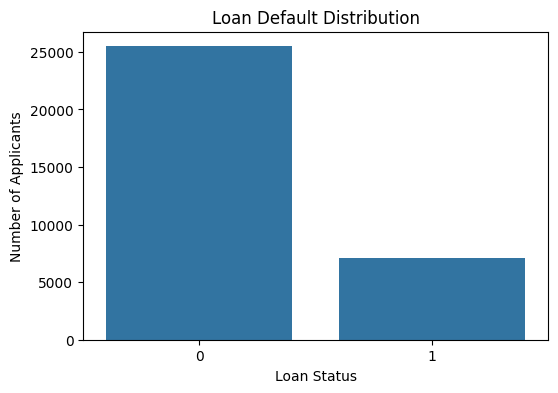

In [241]:
#Exploratory Data Analysis
#Target distribution
plt.figure(figsize=(6,4))

sns.countplot(
    x="loan_status",
    data=df
)

plt.title("Loan Default Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")

plt.show()

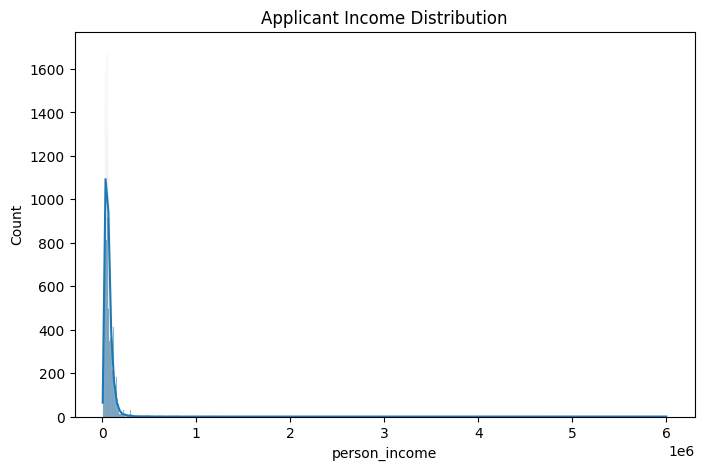

In [242]:
#Income distribution

plt.figure(figsize=(8,5))

sns.histplot(
    df["person_income"],
    kde=True
)

plt.title("Applicant Income Distribution")

plt.show()

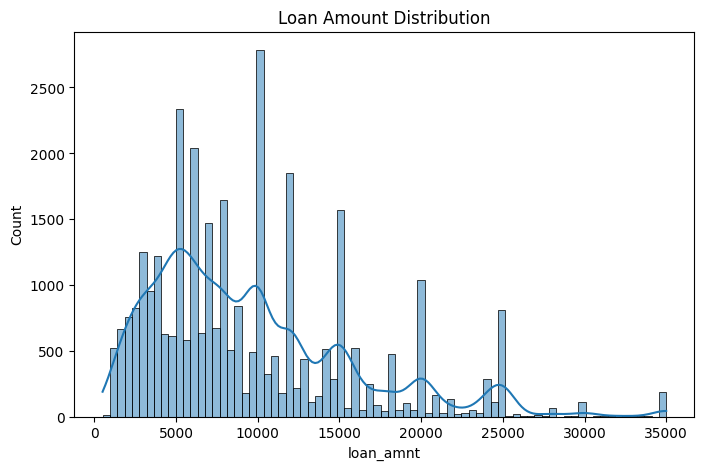

In [243]:
#Loan amount

plt.figure(figsize=(8,5))

sns.histplot(
    df["loan_amnt"],
    kde=True
)

plt.title("Loan Amount Distribution")

plt.show()

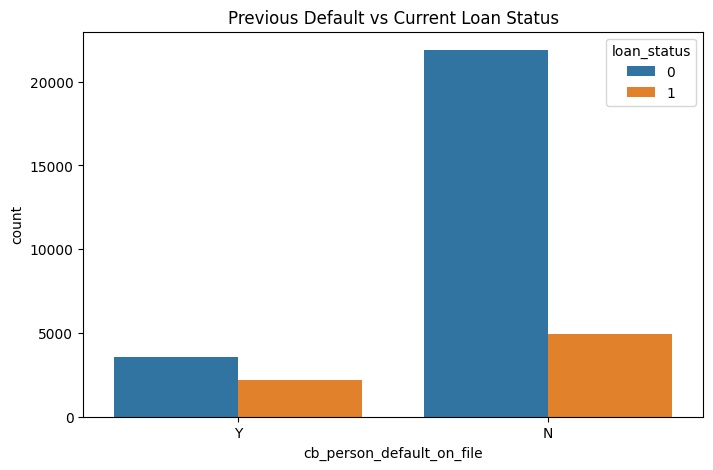

In [244]:
# Credit history vs default

plt.figure(figsize=(8,5))

sns.countplot(
    x="cb_person_default_on_file",
    hue="loan_status",
    data=df
)

plt.title(
    "Previous Default vs Current Loan Status"
)

plt.show()

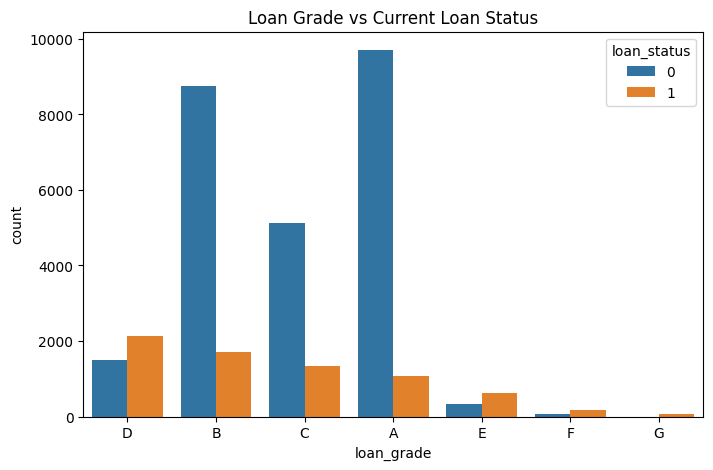

In [245]:
# Loan grade vs default

plt.figure(figsize=(8,5))

sns.countplot(
    x="loan_grade",
    hue="loan_status",
    data=df
)

plt.title(
    "Loan Grade vs Current Loan Status"
)

plt.show()


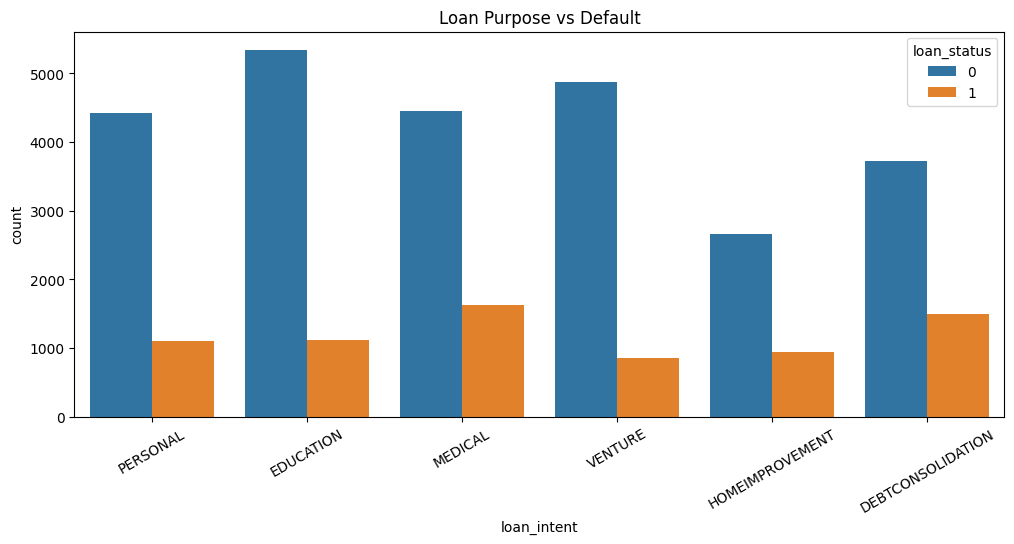

In [246]:
#Loan intent vs default
plt.figure(figsize=(12,5))

sns.countplot(
    x="loan_intent",
    hue="loan_status",
    data=df
)

plt.xticks(rotation=30)

plt.title("Loan Purpose vs Default")

plt.show()

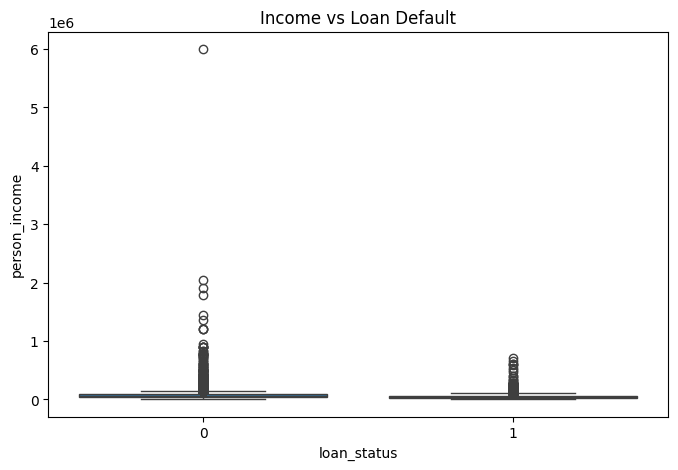

In [247]:
# Income vs loan status
plt.figure(figsize=(8,5))

sns.boxplot(
    x="loan_status",
    y="person_income",
    data=df
)

plt.title("Income vs Loan Default")

plt.show()

In [248]:
# DATA PREPROCESSING
# Remove unnecessary data

# First check duplicates:

df.duplicated().sum()



np.int64(165)

In [249]:
# Remove:

df = df.drop_duplicates()

In [250]:
# Separate features and target
# Our target is:
# loan_status
X = df.drop("loan_status", axis=1)

y = df["loan_status"]

In [251]:
X.head()


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,0.55,Y,4


In [252]:
y.head()

,loan_status
0,1
1,0
2,1
3,1
4,1


In [253]:
# Identify categorical columns

categorical_features = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file"
]

In [254]:
# Numerical features:

numerical_features = [
    "person_age",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length"
]

In [255]:
# Create preprocessing pipeline
# numerical
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [256]:
# Categorical:

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [257]:
# Combine:

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [258]:
# Train-test split
# 80% training
# 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


In [259]:
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (25932, 11)
Testing: (6484, 11)


In [260]:
#Create Random Forest model
rf_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,              #creates 300 decision trees.
                max_depth=12,                  #limits tree depth and helps control overfitting.
                random_state=42,
                class_weight="balanced",       #useful because default/non-default classes may not be equally represented.
                n_jobs=-1
            )
        )
    ]
)

In [261]:
# Train the model
rf_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', max_depth=12,
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

In [262]:
# Make predictions
y_pred = rf_model.predict(
    X_test
)

In [263]:
y_probability = rf_model.predict_proba(
    X_test
)[:, 1]

In [264]:
# Accuracy
accuracy = accuracy_score(
    y_test,
    y_pred
)

print(
    "Accuracy:",
    accuracy
)

Accuracy: 0.9187230104873535


In [265]:
# Precision
precision = precision_score(
    y_test,
    y_pred
)

print(
    "Precision:",
    precision
)

Precision: 0.9075937785910339


In [266]:
# Recall
recall = recall_score(
    y_test,
    y_pred
)

print(
    "Recall:",
    recall
)

Recall: 0.6995768688293371


In [267]:
# F1 score
f1 = f1_score(
    y_test,
    y_pred
)

print(
    "F1 Score:",
    f1
)

F1 Score: 0.7901234567901234


In [268]:
# ROC-AUC
roc_auc = roc_auc_score(
    y_test,
    y_probability
)

print(
    "ROC-AUC:",
    roc_auc
)

ROC-AUC: 0.9138700604767422


In [269]:
# Print all metrics
print("===== RANDOM FOREST RESULTS =====")

print(
    f"Accuracy  : {accuracy:.4f}"
)

print(
    f"Precision : {precision:.4f}"
)

print(
    f"Recall    : {recall:.4f}"
)

print(
    f"F1 Score  : {f1:.4f}"
)

print(
    f"ROC-AUC   : {roc_auc:.4f}"
)

===== RANDOM FOREST RESULTS =====
Accuracy  : 0.9187
Precision : 0.9076
Recall    : 0.6996
F1 Score  : 0.7901
ROC-AUC   : 0.9139


In [270]:
# Classification report
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.92      0.98      0.95      5066
           1       0.91      0.70      0.79      1418

    accuracy                           0.92      6484
   macro avg       0.91      0.84      0.87      6484
weighted avg       0.92      0.92      0.91      6484



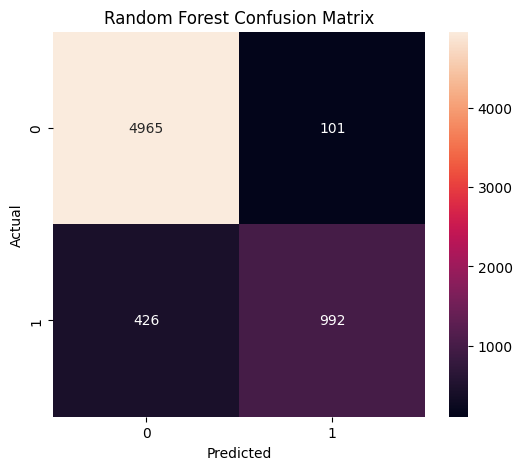

In [271]:
# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "Random Forest Confusion Matrix"
)

plt.show()

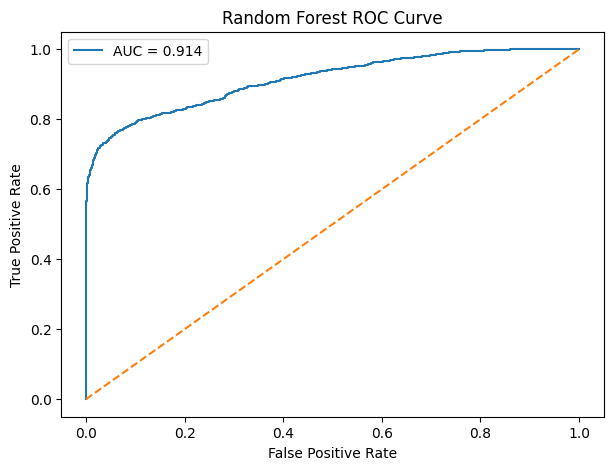

In [272]:
# ROC Curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {roc_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Random Forest ROC Curve"
)

plt.legend()

plt.show()

In [273]:
# Feature importance

# First get the trained Random Forest:

rf_classifier = (
    rf_model
    .named_steps["classifier"]
)

In [274]:
# Get preprocessing:

preprocessor_fitted = (
    rf_model
    .named_steps["preprocessor"]
)

In [275]:
# Get feature names:

feature_names = (
    preprocessor_fitted
    .get_feature_names_out()
)

In [276]:
# Importance:

importance = (
    rf_classifier
    .feature_importances_
)

In [277]:
# Create DataFrame:

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

In [278]:
# Sort:

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "Importance",
        ascending=False
    )
)

In [279]:
feature_importance_df.head(15)

,Feature,Importance
4,num__loan_percent_income,0.307324
3,num__loan_int_rate,0.138798
19,cat__loan_grade_D,0.085215
2,num__loan_amnt,0.076007
9,cat__person_home_ownership_RENT,0.062224
1,num__person_emp_length,0.035285
6,cat__person_home_ownership_MORTGAGE,0.034388
16,cat__loan_grade_A,0.030919
0,num__person_age,0.028760
18,cat__loan_grade_C,0.024054


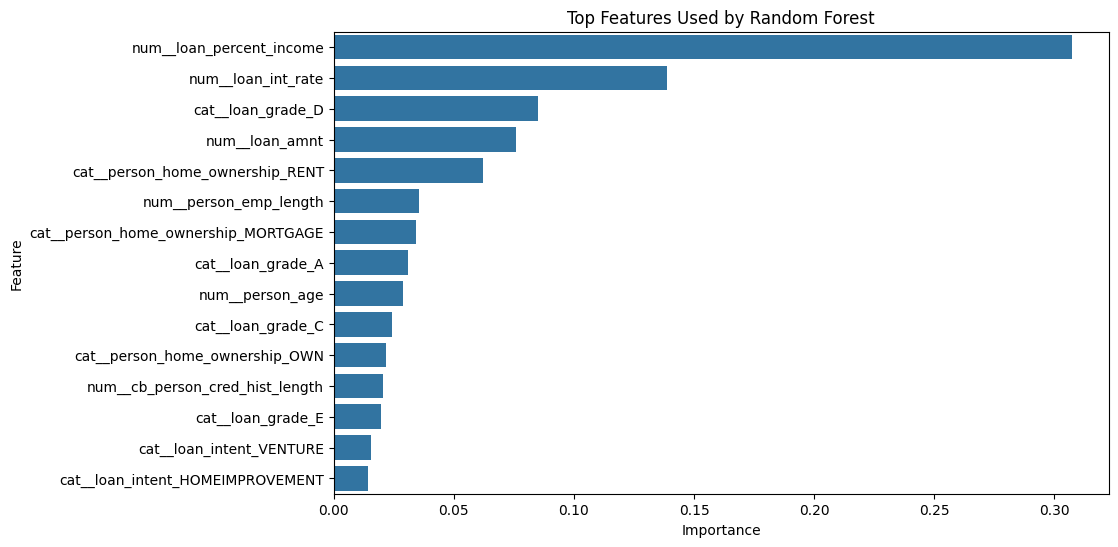

In [280]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title(
    "Top Features Used by Random Forest"
)

plt.show()

In [281]:
# Test with a new applicant

# Before building Streamlit, test the model manually

new_applicant = pd.DataFrame({
    "person_age": [30],
    "person_income": [60000],
    "person_home_ownership": ["RENT"],
    "person_emp_length": [5],
    "loan_intent": ["EDUCATION"],
    "loan_grade": ["B"],
    "loan_amnt": [10000],
    "loan_int_rate": [10.5],
    "loan_percent_income": [0.17],
    "cb_person_default_on_file": ["N"],
    "cb_person_cred_hist_length": [6]
})

In [282]:
prediction = rf_model.predict(
    new_applicant
)[0]

In [283]:
probability = rf_model.predict_proba(
    new_applicant
)[0][1]

In [284]:
print(
    "Prediction:",
    prediction
)

print(
    "Default Probability:",
    probability
)

Prediction: 0
Default Probability: 0.24917705990651584


In [285]:
# Create risk levels

# We'll use project-defined thresholds:

if probability < 0.30:
    risk = "Low Risk"

elif probability < 0.60:
    risk = "Medium Risk"

else:
    risk = "High Risk"

In [286]:
# Save the model

joblib.dump(
    rf_model,
    "loan_risk_model.pkl"
)

['loan_risk_model.pkl']

In [287]:
import os

os.path.exists(
    "loan_risk_model.pkl"
)

True

In [288]:
# Download model
from google.colab import files

files.download(
    "loan_risk_model.pkl"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [292]:
import sklearn
print(sklearn.__version__)

1.6.1
